# Star, Galaxy or Quasar? Teaching a Computer to Read the Night Sky

**Goal:** predict the type of object in the sky (`class`: STAR, GALAXY or QSO = quasar) from telescope measurements.

**Type of problem:** supervised **classification** (the model learns from labelled objects, then predicts a category).

**Data:** Stellar Classification Dataset (SDSS17), 100,000 objects observed by the Sloan Digital Sky Survey.

The reusable code lives in `src/`:
- `src/data.py`: download and clean the data
- `src/features.py`: color features and the feature/target split
- `src/models.py`: models, evaluation and tuning

Plan:
1. Load the data
2. Explore it
3. Clean it and create features
4. Split into train / test
5. Baseline + models
6. Tune the best model
7. What mattered most (feature importance)
8. The twist: colors only, without redshift
9. Key numbers

> 💡 **In simple words**
>
> A telescope sees a dot of light. Is it a **star** (a sun like ours, close by), a **galaxy** (billions of stars, far away) or a **quasar** (a giant glowing black hole, super far away)?
>
> In this notebook we teach a computer to answer that question by showing it 100,000 examples where we already know the answer. Each section below has a 💡 note like this one explaining what happens, and a 📌 note after the important results explaining what they mean.

## 0. Setup

> 💡 **In simple words**
>
> Before we start, we load our **tools** (like opening a toolbox):
> - `pandas` works with tables, `matplotlib` and `seaborn` draw charts, `sklearn` (scikit-learn) has the machine learning models.
> - We also load **our own helper code** from the `src` folder, so this notebook stays short and easy to read:
>   - `src/data.py`: downloads and cleans the data
>   - `src/features.py`: creates the color clues
>   - `src/models.py`: the models, how we score them and how we tune them

In [1]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))  # lets the notebook import from src/

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay, f1_score
from sklearn.model_selection import train_test_split

from src.data import load_raw, clean
from src.features import add_color_features, split_features_target, COLOR_COLUMNS
from src.models import RANDOM_STATE, get_models, evaluate_models, tune_gradient_boosting

sns.set_theme(style="whitegrid")

## 1. Load the data

> 💡 **In simple words**
>
> We download the table of 100,000 sky objects from Kaggle (only the first time; after that it's saved on the computer).
> - `df` is our table. Each **row** is one object, each **column** is one measurement.
> - `df.shape` tells us the size: 100,000 rows and 18 columns.
> - `df.head()` shows the first 5 rows, so we can see what the data looks like.
> - `df.info()` shows each column's type and confirms there are **no missing values**.

In [2]:
df = load_raw()
print(df.shape)
df.head()

(100000, 18)


,obj_ID,alpha,delta,u,g,r,i,z,run_ID,rerun_ID,cam_col,field_ID,spec_obj_ID,class,redshift,plate,MJD,fiber_ID
0,1.237661e+18,135.689107,32.494632,23.87882,22.27530,20.39501,19.16573,18.79371,3606,301,2,79,6.543777e+18,GALAXY,0.634794,5812,56354,171
1,1.237665e+18,144.826101,31.274185,24.77759,22.83188,22.58444,21.16812,21.61427,4518,301,5,119,1.176014e+19,GALAXY,0.779136,10445,58158,427
2,1.237661e+18,142.188790,35.582444,25.26307,22.66389,20.60976,19.34857,18.94827,3606,301,2,120,5.152200e+18,GALAXY,0.644195,4576,55592,299
3,1.237663e+18,338.741038,-0.402828,22.13682,23.77656,21.61162,20.50454,19.25010,4192,301,3,214,1.030107e+19,GALAXY,0.932346,9149,58039,775
4,1.237680e+18,345.282593,21.183866,19.43718,17.58028,16.49747,15.97711,15.54461,8102,301,3,137,6.891865e+18,GALAXY,0.116123,6121,56187,842


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 18 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   obj_ID       100000 non-null  float64
 1   alpha        100000 non-null  float64
 2   delta        100000 non-null  float64
 3   u            100000 non-null  float64
 4   g            100000 non-null  float64
 5   r            100000 non-null  float64
 6   i            100000 non-null  float64
 7   z            100000 non-null  float64
 8   run_ID       100000 non-null  int64  
 9   rerun_ID     100000 non-null  int64  
 10  cam_col      100000 non-null  int64  
 11  field_ID     100000 non-null  int64  
 12  spec_obj_ID  100000 non-null  float64
 13  class        100000 non-null  object 
 14  redshift     100000 non-null  float64
 15  plate        100000 non-null  int64  
 16  MJD          100000 non-null  int64  
 17  fiber_ID     100000 non-null  int64  
dtypes: float64(10), int64(7),

### 📖 Guide: what the rows and columns mean

#### 📄 Rows

**Each row is one object in the sky** that the telescope looked at: one star, one galaxy or one quasar. There are **100,000 rows** = 100,000 objects.

Example, the **first row**:

| What | Value | Meaning |
|---|---|---|
| class | GALAXY | It's a galaxy |
| alpha / delta | 135.7 / 32.5 | Where it is in the sky |
| u, g, r, i, z | 23.9, 22.3, 20.4, 19.2, 18.8 | How bright it looks through each color filter |
| redshift | 0.63 | How far away it is (fairly far) |

#### 📊 Columns (18 in total)

**1. 🎯 The answer (what we predict)**

| Column | Meaning |
|---|---|
| **class** | The type of object: `STAR`, `GALAXY` or `QSO` (quasar). This is what the model learns to guess. |

**2. 📍 Where it is in the sky** (like longitude and latitude on a map of the sky)

| Column | Meaning |
|---|---|
| **alpha** | Left–right position in the sky (0 to 360 degrees) |
| **delta** | Up–down position in the sky (−90 to +90 degrees) |

**3. 🌈 Brightness through 5 color filters** (like looking through 5 pairs of colored sunglasses)

| Column | Filter color |
|---|---|
| **u** | Ultraviolet (invisible to our eyes, beyond purple) |
| **g** | Green |
| **r** | Red |
| **i** | Near-infrared (just beyond red, invisible) |
| **z** | Infrared (further beyond red, invisible) |

⚠️ **Tricky part:** in astronomy, a **smaller number means brighter** (like a race: 1st place beats 10th place). So `u = 15` is brighter than `u = 25`.

**4. 📏 Distance**

| Column | Meaning |
|---|---|
| **redshift** | How much the object's light is "stretched" because it's moving away from us. **Bigger number = further away.** Stars ≈ 0, galaxies ≈ 0.5, quasars ≈ 1.6. A **negative** value means it's moving towards us. |

**5. 🗂️ ID / bookkeeping columns (removed in section 3)**

These are like **receipt numbers**: they record *how* the telescope took the measurement, not anything about the object itself.

| Column | Meaning |
|---|---|
| **obj_ID** | The object's ID number in the photo catalog |
| **spec_obj_ID** | The ID number of its distance measurement |
| **run_ID** | Which scan of the sky the photo came from |
| **rerun_ID** | Which version of the photo processing was used |
| **cam_col** | Which of the 6 camera columns took the photo |
| **field_ID** | Which small patch of that scan it's in |
| **plate** | ID of the metal plate used to measure distance (it has holes drilled where objects are) |
| **fiber_ID** | Which glass fiber on that plate carried the object's light |
| **MJD** | The date of the measurement (a day-counting number astronomers use) |

#### ✨ The 4 columns we create (in section 3)

| Column | How it's made | Meaning |
|---|---|---|
| **u_g** | u − g | Ultraviolet vs. green |
| **g_r** | g − r | Green vs. red |
| **r_i** | r − i | Red vs. near-infrared |
| **i_z** | i − z | Near-infrared vs. infrared |

These describe an object's **real color** (more blue or more red), no matter how far away or bright it is. Two of them (**r_i** and **g_r**) turn out to be the model's 2nd and 3rd best clues.

#### 🧠 In one sentence

Each **row** is one sky object; the columns say **where** it is (alpha, delta), **how bright** it looks in 5 colors (u, g, r, i, z), **how far** it is (redshift) and **what it is** (class). The ID columns are just telescope bookkeeping, so we remove them.

## 2. Explore

**What to look for:** how many of each class (is it balanced?) and how redshift differs between classes.

> 💡 **In simple words**
>
> Before teaching the computer, we look at the data **ourselves**, like reading a book before writing a summary.
> - **Bar chart:** how many objects of each type we have.
> - **Box chart:** how far away each type is (redshift = distance).
> - **Color table:** how bright each type is through each color filter.

class
GALAXY    59445
STAR      21594
QSO       18961
Name: count, dtype: int64
class
GALAXY    59.4
STAR      21.6
QSO       19.0
Name: count, dtype: float64


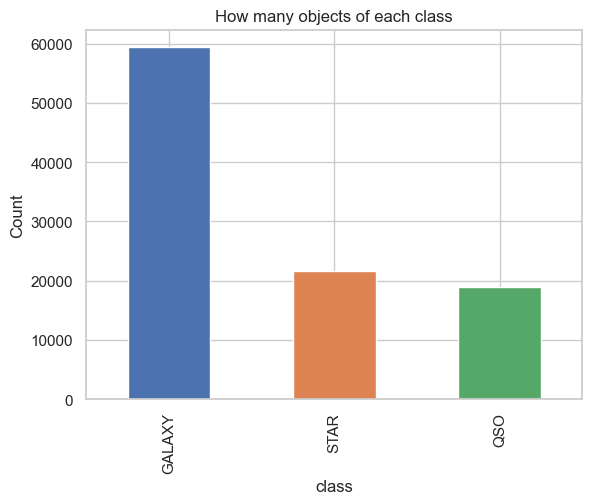

In [4]:
counts = df["class"].value_counts()
print(counts)
print((counts / len(df) * 100).round(1))

counts.plot(kind="bar", color=["#4C72B0", "#DD8452", "#55A868"])
plt.title("How many objects of each class")
plt.ylabel("Count")
plt.show()

> 📌 **What this means**
>
> The classes are **uneven**: 59% galaxies, 22% stars and 19% quasars. A model that always says "galaxy" would already be right 59% of the time, so that's the score to beat.

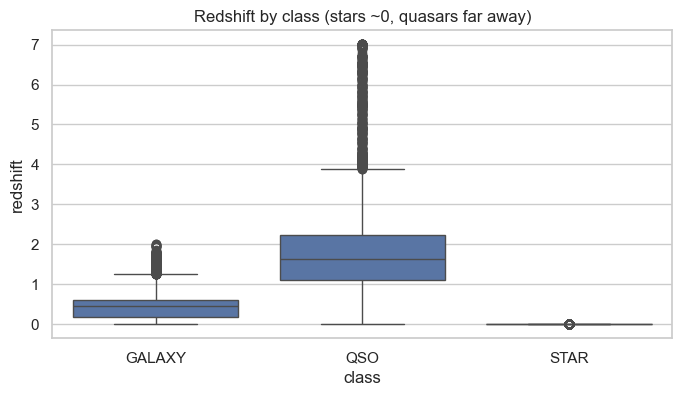

,count,mean,std,min,25%,50%,75%,max
class,,,,,,,,
GALAXY,59445.0,0.422,0.265,-0.010,0.165,0.456,0.595,1.996
QSO,18961.0,1.720,0.914,0.000,1.107,1.617,2.220,7.011
STAR,21594.0,-0.000,0.000,-0.004,-0.000,-0.000,0.000,0.004


In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.boxplot(data=df, x="class", y="redshift", ax=ax)
ax.set_title("Redshift by class (stars ~0, quasars far away)")
plt.show()

df.groupby("class")["redshift"].describe().round(3)

> 📌 **What this means**
>
> Distance separates the types very well: **stars are at about 0** (close by), **galaxies are further** (median about 0.46) and **quasars are much further** (median about 1.62). This already hints that distance will be the model's best clue.

In [6]:
# Brightness in the 5 color filters by class
df.groupby("class")[["u", "g", "r", "i", "z"]].median().round(2)

,u,g,r,i,z
class,,,,,
GALAXY,22.84,21.58,20.10,19.22,18.77
QSO,21.50,21.06,20.77,20.58,20.37
STAR,21.01,19.54,18.96,18.59,18.32


In [7]:
# Fun fact: share of stars with a negative redshift (moving towards us)
(df.loc[df["class"] == "STAR", "redshift"] < 0).mean().round(3)

np.float64(0.634)

> 📌 **What this means**
>
> **Fun fact:** about 63% of stars have a slightly *negative* redshift. That means they're moving **towards** us!

## 3. Clean and create features

- Drop the **ID / bookkeeping columns**: they describe *how* the telescope recorded the object, not the object itself.
- Remove impossible values (one row has -9999 as a placeholder brightness).
- The `class` column stays as text: scikit-learn models handle text labels on their own.
- Add **colors**: astronomers compare brightness between neighbouring filters (u−g, g−r, r−i, i−z), because that says more about an object than raw brightness.

> 💡 **In simple words**
>
> **Cleaning** = tidying the table before using it:
> - We remove 9 ID columns. They're like serial numbers the telescope uses for bookkeeping; they tell us nothing about the object itself.
> - We remove 1 broken row that had a fake value (−9999).
>
> **Creating features** = making new, better clues:
> - We subtract each color from the next one (for example `u − g`). This is how astronomers describe an object's real "color", and it helps the model.
>
> At the end, `X` holds the **clues** and `y` holds the **answers** (star, galaxy or quasar).

In [8]:
print("Missing values:", df.isna().sum().sum())

data = add_color_features(clean(df))
print("Rows left:", len(data))

X, y = split_features_target(data)
X.head()

Missing values: 0
Rows left: 99999


,alpha,delta,u,g,r,i,z,redshift,u_g,g_r,r_i,i_z
0,135.689107,32.494632,23.87882,22.27530,20.39501,19.16573,18.79371,0.634794,1.60352,1.88029,1.22928,0.37202
1,144.826101,31.274185,24.77759,22.83188,22.58444,21.16812,21.61427,0.779136,1.94571,0.24744,1.41632,-0.44615
2,142.188790,35.582444,25.26307,22.66389,20.60976,19.34857,18.94827,0.644195,2.59918,2.05413,1.26119,0.40030
3,338.741038,-0.402828,22.13682,23.77656,21.61162,20.50454,19.25010,0.932346,-1.63974,2.16494,1.10708,1.25444
4,345.282593,21.183866,19.43718,17.58028,16.49747,15.97711,15.54461,0.116123,1.85690,1.08281,0.52036,0.43250


## 4. Split into train and test

`stratify=y` keeps the same class mix in both parts. The test set is only used at the end.

> 💡 **In simple words**
>
> We split the data into two groups, like a student preparing for an exam:
> - **80% = training set** (the practice questions): the model learns from these.
> - **20% = test set** (the real exam): the model has **never seen** these, so they show how good it really is.
>
> `stratify=y` makes sure both groups have the same mix of stars, galaxies and quasars.

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print(X_train.shape, X_test.shape)

(79999, 12) (20000, 12)


## 5. Baseline and models

- **Baseline:** always guess the most common class (GALAXY). The line to beat.
- **Logistic Regression:** a simple, explainable model.
- **KNN (K-Nearest Neighbours):** finds the 5 most similar objects it already knows and copies their most common answer.
- **Random Forest:** many decision trees voting together.
- **Gradient Boosting:** trees that learn from each other's mistakes.

**Judged by:** accuracy, and **macro F1** (treats all 3 classes equally, so the model can't hide a bad quasar score behind lots of galaxies).

> 💡 **In simple words**
>
> This is the **model race**: we train several models and see which one guesses best on the test set.
> - The **baseline** is the "lazy" answer: always say "galaxy". Every real model must beat it.
> - **Accuracy** = % of guesses that were right.
> - **Macro F1** = a fairer score that treats stars, galaxies and quasars equally (important because most objects are galaxies).
> - **Precision** = when the model says a type, how often it is right. **Recall** = of all real objects of a type, how many it found. Both are explained with examples in section 6.

In [10]:
models = get_models()
results_all = evaluate_models(models, X_train, X_test, y_train, y_test)
results_all

,accuracy,macro_precision,macro_recall,macro_F1
model,,,,
Baseline (most common),0.5944,0.1982,0.3333,0.2485
Logistic Regression,0.9584,0.9550,0.9508,0.9522
KNN,0.9444,0.9437,0.9330,0.9381
Random Forest,0.9798,0.9796,0.9735,0.9764
Gradient Boosting,0.9774,0.9769,0.9711,0.9739


> 📌 **What this means**
>
> All four real models **easily beat the lazy guess** (59%). **Random Forest wins with about 98%** correct, very close to Gradient Boosting. Even the simple Logistic Regression gets about 96%, and KNN about 94%.

### 📏 Why KNN needs feature scaling

KNN decides by measuring **how close** two objects are, using all the clues together. But the clues are on very different scales: brightness numbers are around 15–25, while redshift is mostly between 0 and 7. Without scaling, the big brightness numbers drown out redshift, the best clue.

`StandardScaler` puts every clue on the same scale (average 0, spread 1). Below, the same KNN is trained with and without it.

In [11]:
from sklearn.neighbors import KNeighborsClassifier

knn_unscaled = KNeighborsClassifier(n_neighbors=5, n_jobs=-1).fit(X_train, y_train)
knn_scaled = models["KNN"]  # StandardScaler + KNN, already trained above

print(f"KNN without scaling: {accuracy_score(y_test, knn_unscaled.predict(X_test)):.1%}")
print(f"KNN with scaling:    {accuracy_score(y_test, knn_scaled.predict(X_test)):.1%}")

KNN without scaling: 83.7%


KNN with scaling:    94.4%


> 📌 **What this means**
>
> Scaling makes KNN **much** better. Once every clue counts fairly, the closest neighbours really are similar objects. KNN still comes behind Random Forest, because it treats every clue as equally important, while the trees learn that distance matters most.

## 6. Tune the best model (Grid Search + 5-fold Cross-Validation)

> 💡 **In simple words**
>
> Models have **settings**, like the knobs on a radio. Tuning means finding the best settings.
> - **Grid Search** tries every combination from a list (here 8 combinations) and keeps the best one.
> - **5-fold cross-validation** tests each combination on 5 different parts of the training data, so one lucky test can't fool us.
>
> Then we look at the **confusion matrix**: a table that shows exactly which objects the model mixed up.

In [12]:
grid = tune_gradient_boosting(X_train, y_train)

print("Best settings:", grid.best_params_)
print("Best cross-validated macro F1:", round(grid.best_score_, 4))

best_pred = grid.best_estimator_.predict(X_test)
tuned_acc = accuracy_score(y_test, best_pred)
tuned_f1 = f1_score(y_test, best_pred, average="macro")
print(f"Test accuracy after tuning: {tuned_acc:.4f}   macro F1: {tuned_f1:.4f}")

Best settings: {'learning_rate': 0.05, 'max_iter': 200, 'max_leaf_nodes': 63}
Best cross-validated macro F1: 0.9741
Test accuracy after tuning: 0.9791   macro F1: 0.9759


> 📌 **What this means**
>
> Tuning only helped **a tiny bit** (macro F1 from 0.974 to 0.976). The model was already close to its best, so changing the settings couldn't improve it much. Good data and good clues matter more than settings.

              precision    recall  f1-score   support

      GALAXY      0.979     0.986     0.983     11889
         QSO      0.966     0.939     0.952      3792
        STAR      0.990     0.996     0.993      4319

    accuracy                          0.979     20000
   macro avg      0.978     0.973     0.976     20000
weighted avg      0.979     0.979     0.979     20000



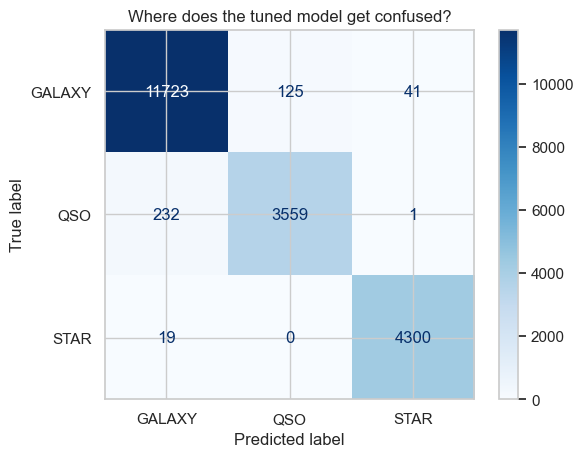

In [13]:
print(classification_report(y_test, best_pred, digits=3))
ConfusionMatrixDisplay.from_predictions(y_test, best_pred, cmap="Blues")
plt.title("Where does the tuned model get confused?")
plt.show()

### 📏 Precision, recall and F1: how good is the model at each type?

The table above (`classification_report`) grades the tuned model **separately for each type**. It uses three scores:

| Score | The question it answers | Formula |
|---|---|---|
| **Precision** | When the model says *"quasar"*, how often is it **right**? | $\frac{TP}{TP + FP}$ |
| **Recall** | Of all the **real** quasars, how many did the model **find**? | $\frac{TP}{TP + FN}$ |
| **F1-score** | One balanced score that combines precision and recall | $2 \times \frac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}$ |

- **TP** (true positive) = a real quasar the model called a quasar ✅
- **FP** (false positive) = something else the model wrongly called a quasar (a false alarm) ❌
- **FN** (false negative) = a real quasar the model missed ❌

#### 🔍 Example with our quasars (numbers from the confusion matrix)

- The model said **"quasar" 3,684 times**: 3,559 were real quasars, 125 were galaxies.
  → **Precision = 3,559 ÷ 3,684 = 96.6%**. When it says "quasar", it's almost always right.
- There were **3,792 real quasars**: the model found 3,559 and missed 233 (232 called galaxies, 1 called a star).
  → **Recall = 3,559 ÷ 3,792 = 93.9%**. It finds most quasars but misses a few.
- **F1 = 0.952**: the balance of the two.

#### 📌 What this means

| Type | Precision | Recall | F1 | In simple words |
|---|---|---|---|---|
| ⭐ Star | 99.0% | 99.6% | 0.993 | Almost perfect |
| 🌌 Galaxy | 97.9% | 98.6% | 0.983 | Excellent |
| 💥 Quasar | 96.6% | 93.9% | 0.952 | Very good, but it **misses some quasars** (the closer ones) |

- **Quasars have the lowest recall**: that's the model's weak spot, the same mix-up we saw in the confusion matrix.
- **Which matters more here?** If astronomers want to *find every quasar*, **recall** matters most (missing one is costly). If they want to *avoid wasting expensive telescope time* on objects that aren't quasars, **precision** matters most.
- **Macro F1** (used throughout this notebook) is simply the **average F1 of the 3 types**, so stars, galaxies and quasars count equally even though there are many more galaxies.

> 📌 **How to read the confusion matrix**
>
> - **Rows** = the real type. **Columns** = what the model guessed.
> - The **diagonal** (top-left to bottom-right) = correct guesses. Everything else = mistakes.
>
> **What it shows:** stars are almost always right (99.6%). The biggest mistake is **232 quasars guessed as galaxies**. Surprisingly, quasars are almost never confused with stars, even though both look like dots.

In [14]:
# The quasars mistaken for galaxies are the closer ones
missed = X_test[(y_test == "QSO") & (best_pred == "GALAXY")]
print("Median redshift of missed quasars:", round(missed["redshift"].median(), 2))
print("Median redshift of all quasars:   ", round(X_test.loc[y_test == "QSO", "redshift"].median(), 2))

Median redshift of missed quasars: 0.59
Median redshift of all quasars:    1.64


> 📌 **What this means**
>
> The quasars the model got wrong are the **closer** ones (distance about 0.59 instead of 1.64). At that distance, quasars and galaxies overlap, so the distance clue stops helping and the model gets confused.

### 🏆 The winner up close: Random Forest

Tuning was done on Gradient Boosting, but the overall winner of the model race is the **Random Forest**. These are the numbers shown in the slides.

              precision    recall  f1-score   support

      GALAXY      0.979     0.987     0.983     11889
         QSO      0.967     0.934     0.950      3792
        STAR      0.993     1.000     0.996      4319

    accuracy                          0.980     20000
   macro avg      0.980     0.974     0.976     20000
weighted avg      0.980     0.980     0.980     20000



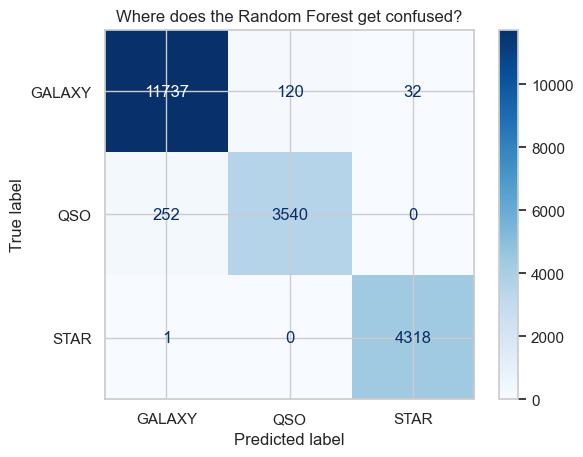

In [15]:
rf = models["Random Forest"]  # already trained by evaluate_models above
rf_pred = rf.predict(X_test)

print(classification_report(y_test, rf_pred, digits=3))
ConfusionMatrixDisplay.from_predictions(y_test, rf_pred, cmap="Blues")
plt.title("Where does the Random Forest get confused?")
plt.show()

> 📌 **What this means**
>
> The Random Forest tells the same story as the tuned model:
> - **Stars are easy:** only 1 of 4,319 was missed.
> - **Biggest mistake:** 252 quasars called galaxies, and never a quasar called a star.
> - **Quasars:** precision 96.7% (when it says "quasar", it's almost always right) and recall 93.4% (it finds most of them).

In [16]:
# Who are the missed quasars? Compare them with the quasars it got right and with real galaxies
rf_results = X_test.assign(real=y_test, guess=rf_pred)
groups = {
    "Quasars called galaxies": rf_results[(rf_results.real == "QSO") & (rf_results.guess == "GALAXY")],
    "Quasars found": rf_results[(rf_results.real == "QSO") & (rf_results.guess == "QSO")],
    "Galaxies found": rf_results[(rf_results.real == "GALAXY") & (rf_results.guess == "GALAXY")],
}
pd.DataFrame({name: {"objects": len(g),
                     "median redshift": g["redshift"].median(),
                     "median u_g color": g["u_g"].median(),
                     "median g_r color": g["g_r"].median()}
              for name, g in groups.items()}).T.round(2)

,objects,median redshift,median u_g color,median g_r color
Quasars called galaxies,252.0,0.60,0.91,0.77
Quasars found,3540.0,1.71,0.38,0.20
Galaxies found,11737.0,0.46,1.67,1.42


> 📌 **What this means**
>
> The missed quasars sit **between** normal quasars and galaxies:
> - **Distance:** they are much closer than typical quasars, at the same distance as many galaxies.
> - **Color:** they are less blue than typical quasars (a bigger color number means redder), so their color looks more like a galaxy's.
>
> So these quasars really do look like galaxies in both main clues. That's why the model gets them wrong.

## 7. What mattered most?

Uses the Random Forest's feature importance (how much each feature helped the trees split the data).

> 💡 **In simple words**
>
> **Feature importance** tells us which clues the model used the most to make its decisions. A longer bar means a more useful clue.

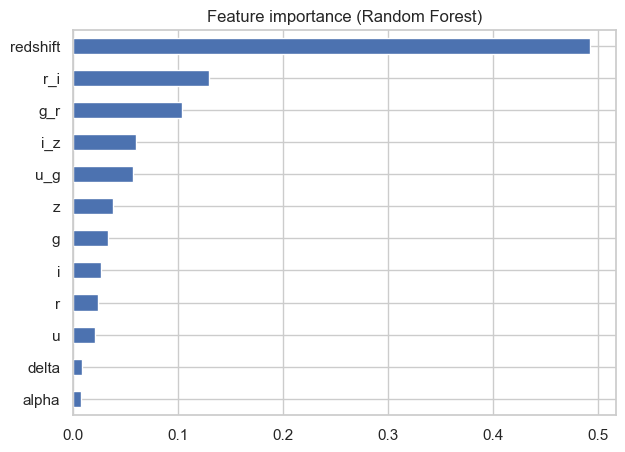

redshift    0.492714
r_i         0.129706
g_r         0.103484
dtype: float64

In [17]:
rf = models["Random Forest"]
importance = pd.Series(rf.feature_importances_, index=X_train.columns).sort_values()
importance.plot(kind="barh", figsize=(7, 5))
plt.title("Feature importance (Random Forest)")
plt.show()
top3 = importance.sort_values(ascending=False).head(3)
top3

> 📌 **What this means**
>
> **Distance (redshift) does about half the work** on its own (49%). The next two best clues are **colors we created ourselves** (`r_i` and `g_r`), so the feature engineering paid off.

## 8. The twist: can we do it with colors only?

Redshift comes from **spectroscopy**, which is slow and expensive. Colors (u, g, r, i, z) come from cheap photos.
How much accuracy do we lose without redshift?

> 💡 **In simple words**
>
> Distance (redshift) is a great clue, but measuring it is **slow and expensive**. Colors come from normal photos and are **cheap and fast**.
>
> So we run the same race again, giving the models **only the colors**, to see how much worse they do without the expensive clue.

In [18]:
results_colors = evaluate_models(get_models(), X_train[COLOR_COLUMNS], X_test[COLOR_COLUMNS], y_train, y_test)

comparison = results_all.join(results_colors, lsuffix=" (all)", rsuffix=" (colors only)")
comparison

,accuracy (all),macro_precision (all),macro_recall (all),macro_F1 (all),accuracy (colors only),macro_precision (colors only),macro_recall (colors only),macro_F1 (colors only)
model,,,,,,,,
Baseline (most common),0.5944,0.1982,0.3333,0.2485,0.5944,0.1982,0.3333,0.2485
Logistic Regression,0.9584,0.9550,0.9508,0.9522,0.7577,0.7131,0.6745,0.6704
KNN,0.9444,0.9437,0.9330,0.9381,0.8761,0.8515,0.8328,0.8415
Random Forest,0.9798,0.9796,0.9735,0.9764,0.8840,0.8597,0.8424,0.8504
Gradient Boosting,0.9774,0.9769,0.9711,0.9739,0.8856,0.8620,0.8458,0.8533


> 📌 **What this means**
>
> Without distance, the best model drops from **98% to about 89%**. That's still great, and far better than the 59% lazy guess.
>
> **Real-world use:** telescopes take millions of photos. A colors-only model could sort them quickly, so scientists only spend time and money measuring the interesting ones.

## 9. Key numbers

> 💡 **In simple words**
>
> A short summary of the most important results, the numbers used in the presentation.

In [19]:
best_name = results_all["macro_F1"].idxmax()
print("Baseline accuracy:              ", f"{results_all.loc['Baseline (most common)', 'accuracy']:.1%}")
print("Best untuned model:             ", best_name, f"{results_all.loc[best_name, 'accuracy']:.1%}")
print("Gradient Boosting before tuning:", f"{results_all.loc['Gradient Boosting', 'macro_F1']:.4f} macro F1")
print("Gradient Boosting after tuning: ", f"{tuned_f1:.4f} macro F1, {tuned_acc:.1%} accuracy")
print("Top 3 features:                 ", ", ".join(top3.index))
print("Best colors-only accuracy:      ", f"{results_colors['accuracy'].max():.1%}")

Baseline accuracy:               59.4%
Best untuned model:              Random Forest 98.0%
Gradient Boosting before tuning: 0.9739 macro F1
Gradient Boosting after tuning:  0.9759 macro F1, 97.9% accuracy
Top 3 features:                  redshift, r_i, g_r
Best colors-only accuracy:       88.6%


## Conclusions

- Every model easily beats the baseline; **Random Forest** is best at about **98%** accuracy.
- **Redshift (distance)** does about half the work. The next best clues are two of the engineered colors (r−i, g−r).
- Most mistakes are **quasars labelled as galaxies**, almost never as stars. The missed quasars are the *closer* ones, where quasar and galaxy redshifts overlap.
- **Colors only** (no expensive spectroscopy) still reaches about **89%**, useful for sorting huge photo surveys before deciding what to measure in detail.
- Surprise: most stars have a slightly *negative* redshift, meaning they're moving **towards** us.